# Custom passives: a spiral capacitor and a tunable resonator

Two components that are not in the library, written as short Python files in `examples/custom_component/`:

- `spiral_capacitor.py`: a two-pin capacitor made of two interleaved spirals. It goes in series in a CPW line.
- `tunable_resonator.py`: a lambda/4 CPW resonator shorted to ground through an array of Quantcore SQUIDs, so its
  frequency follows the flux.

This notebook puts the capacitor between a pad and a resonator, hangs the tunable resonator on a feedline, builds the
chip, runs DRC and the LOM (no FEM), and plots the resonator frequency against flux. Guides:
`docs/library/custom-components/spiral-capacitor.md` and `tunable-resonator.md`.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples"))  # examples/ first: `custom_component.<module>`
LIVE = os.environ.get("QCC_LIVE", "1") != "0"  # QCC_LIVE=0: headless, nothing is sent to KLayout
IMG = ROOT / "docs" / "images" / "custom-components"
IMG.mkdir(parents=True, exist_ok=True)

import _common as C
from custom_component.spiral_capacitor import TwistedSpiralCapacitor
from custom_component.tunable_resonator import TunableResonator

from quantcore_circuits import layouts
from quantcore_circuits.designer import Designer
from quantcore_circuits.live.snapshot import snapshot

# The files live outside the library folders, so register them once. Copied into src/quantcore_circuits/layouts/others/
# they are found automatically and this line is not needed.
layouts.register_pcell_classes([TwistedSpiralCapacitor, TunableResonator])
CAP = "custom_component.spiral_capacitor.TwistedSpiralCapacitor"
TUNE = "custom_component.tunable_resonator.TunableResonator"

## 1 The chip

One die with two separate circuits: a chain (pad, spiral capacitor, resonator) on the upper half and a feedline with
the tunable resonator on the lower half.

In [2]:
d = Designer("custom_passives", box=(0, 0, 7500, 5000), chip={"name_chip": "P2B"}, live=LIVE)
with d.batch():
    # chain: pad -> spiral capacitor -> lambda/4 resonator with a shorted free end
    pad_in = d.add("PAD_IN", "BondPad", at=(1125, 3600), rot=270, edge="auto")
    cap = d.add("C1", CAP, at=(2600, 3600), turns=1.0)
    d.route("IN", pad_in.a, cap.a)
    d.route("R_CAP", cap.b, Designer.free_end((4000, 3600), dir=0, term=0), meander=4000, r=50)
    # feedline with the tunable resonator as a hanger
    pad_w = d.add("PAD_W", "BondPad", at=(1125, 1500), rot=270, edge="auto")
    pad_e = d.add("PAD_E", "BondPad", at=(6375, 1500), rot=90, edge="auto")
    fl = d.route("FL", pad_w.a, pad_e.a)
    tune = d.add("TR", TUNE, at=(3300, 2000))
    d.route("R_TR", tune.a, fl.hanger(near=(2800, 1500), length=500, side="left", end="open"))
    pad_f = d.add("PAD_F", "BondPad", at=(6375, 2900), rot=90, edge="auto")
    d.route("FLUX", tune.flux, pad_f.a)
res = d.show()
print("routes (um):", {k: round(v) for k, v in d.result.route_lengths().items()})

routes (um): {'IN': 1338, 'R_CAP': 4000, 'FL': 5050, 'R_TR': 1636, 'FLUX': 3503}


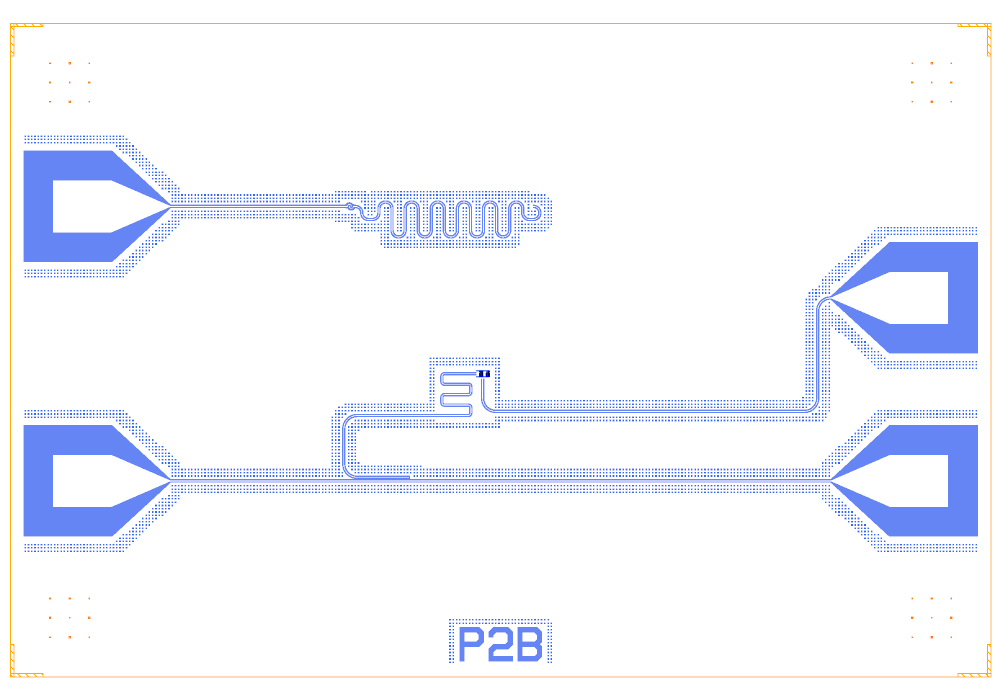

In [3]:
snapshot(d.result, str(IMG / "tunable_chip.png"), size=(1000, 700))
display(Image(str(IMG / "tunable_chip.png"), width=900))

## 2 The spiral capacitor

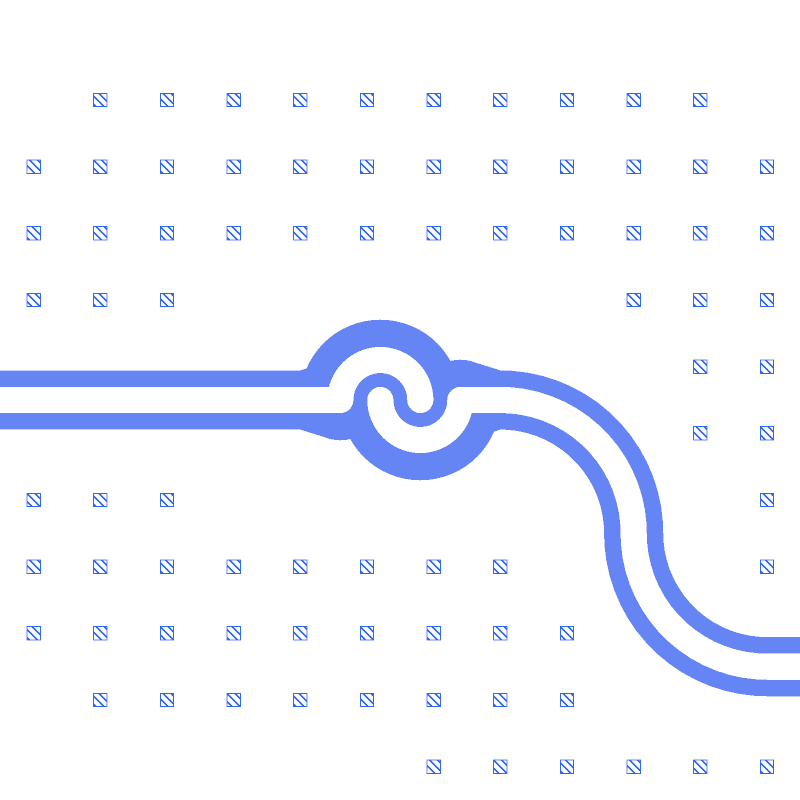

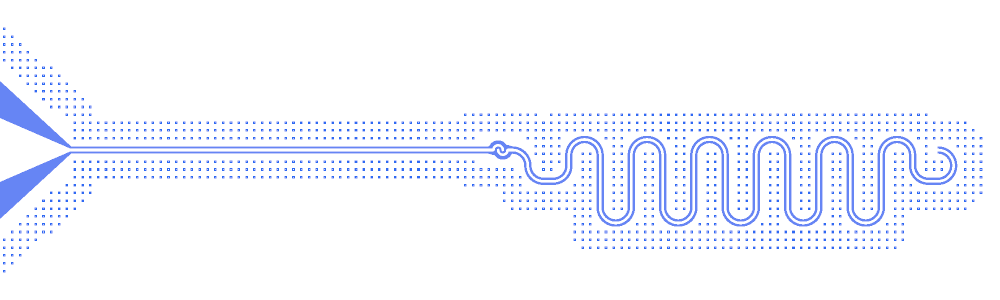

In [4]:
snapshot(d.result, str(IMG / "spiral_zoom.png"), size=(800, 800), box=(2450, 3450, 2750, 3750))
display(Image(str(IMG / "spiral_zoom.png"), width=520))
snapshot(d.result, str(IMG / "spiral_chain.png"), size=(1000, 300), box=(1000, 3350, 4200, 3850))
display(Image(str(IMG / "spiral_chain.png"), width=900))

The pins `a` and `b` are the two ends of the line that the routes `IN` and `R_CAP` connect to. The DRC checks the whole chip:

In [5]:
print(d.drc())

DRC clean


### What the LOM says about the capacitor

The chain is one circuit: the 50 ohm pad port, the capacitor, and the lambda/4 resonator to ground. `select` limits the
LOM to it, because the chip holds a second circuit that is not connected to it.

In [6]:
chain = ["PAD_IN", "C1", "IN", "R_CAP"]
lb1 = d.lom(select=chain)
C.show_netlist(lb1)
res1 = C.simulate_lom(lb1, d.design)
display(Markdown(C.modes_md(res1)))
c_fF = lb1.model.branches["C_C1"].value["estimate"]
print(f"spiral capacitor: C = {c_fF:.1f} fF ({lb1.model.branches['C_C1'].value['estimate_source']})")

**3 nodes · 3 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `C1.a` | `PAD_IN.pad`, `C1.a` |
| `C1.b` | `C1.b` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_IN` | R | `C1.a` – `gnd` | 50 Ω |
| `C_C1` | C | `C1.a` – `C1.b` | 27 fF |
| `R_CAP` | TLres | `C1.b` – `gnd` | lambda/4, 4000 µm, 7.877 GHz |

**Unconnected ports:** none

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| R_CAP | resonator | 7.5330 | 41.1 | 0.0 | R_CAP 1.00 |

spiral capacitor: C = 27.0 fF (rough: coplanar-strip gap over 304 um of spiral gap)


The capacitance follows the spiral length, so the number of turns is the knob. Each row is a rebuild and a LOM:

In [7]:
rows = ["| turns | C (fF) | f_r (GHz) | kappa (MHz) |", "|---|---|---|---|"]
for turns in (0.5, 1.0, 1.5, 2.0, 3.0):
    cap.set(turns=turns)
    d.show()
    lb = d.lom(select=chain)
    m = C.simulate_lom(lb, d.design).modes[0]
    c_val = lb.model.branches["C_C1"].value["estimate"]
    rows.append(f"| {turns:g} | {c_val:.1f} | {m.f_GHz:.3f} | {m.kappa_MHz:.1f} |")
cap.set(turns=1.0)
d.show()
display(Markdown("\n".join(rows)))

| turns | C (fF) | f_r (GHz) | kappa (MHz) |
|---|---|---|---|
| 0.5 | 11.0 | 7.731 | 7.6 |
| 1 | 27.0 | 7.533 | 41.1 |
| 1.5 | 48.0 | 7.298 | 113.8 |
| 2 | 75.0 | 7.031 | 236.7 |
| 3 | 150.0 | 6.444 | 645.7 |

## 3 The tunable resonator

The meander is the CPW; the SQUID array is at the right end of the cell, and the flux line passes below it.

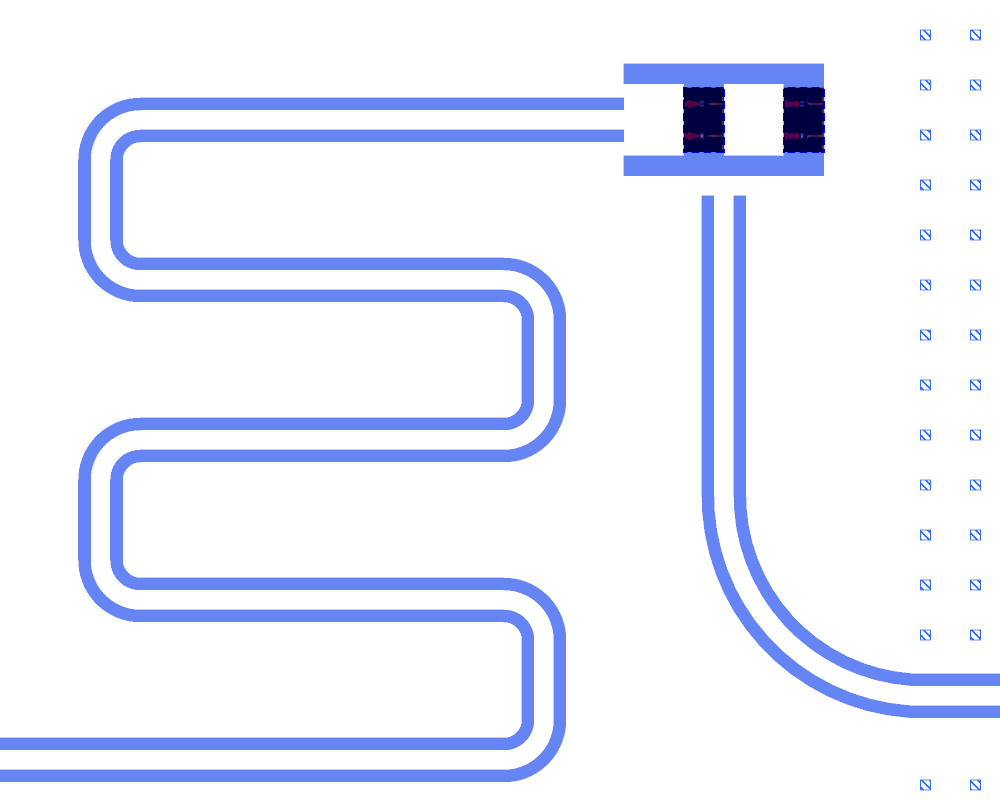

In [8]:
snapshot(d.result, str(IMG / "tunable_zoom.png"), size=(1000, 800), box=(3250, 1980, 3750, 2380))
display(Image(str(IMG / "tunable_zoom.png"), width=800))

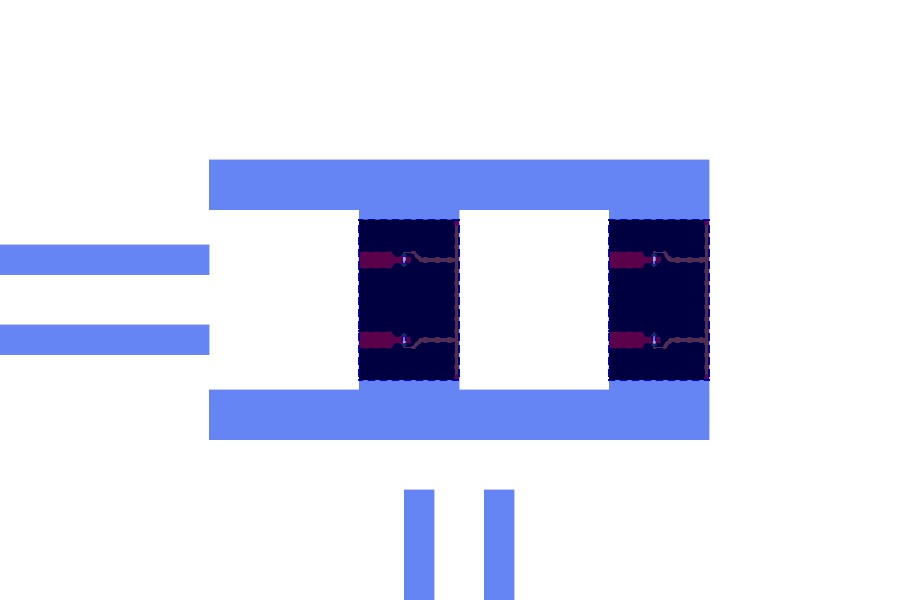

In [9]:
snapshot(d.result, str(IMG / "tunable_squids.png"), size=(900, 600), box=(3520, 2260, 3700, 2380))
display(Image(str(IMG / "tunable_squids.png"), width=700))

### What the LOM says about the tunable resonator

The LOM adds the array as extra line at the shorted end, so it needs the length of the route that finishes the
resonator. Give it that (`route_um`), then sweep the flux. `flux_phi0` is a design value of the instance's `junction`.

In [10]:
route_um = d.result.route_lengths()["R_TR"]
tune.set(route_um=route_um)
hang = ["PAD_W", "PAD_E", "FL", "TR", "R_TR"]
phis = np.round(np.linspace(0, 0.45, 10), 3)
f_lom, f_qucat, l_arr = [], [], []
for phi in phis:
    tune.set(junction={"flux_phi0": float(phi)})
    d.show()
    lb = d.lom(select=hang)
    f_lom.append(lb.model.branches["TR"].value["f_GHz"])
    f_qucat.append(C.simulate_lom(lb, d.design).modes[0].f_GHz)
    l_arr.append(2 * 1.0 / abs(np.cos(np.pi * phi)))  # N * L_J0 / |cos(pi phi)|, N = 2, L_J0 = 1 nH
tune.set(junction={"flux_phi0": 0.0})
d.show()
lb0 = d.lom(select=hang)
C.show_netlist(lb0)
table = ["| flux (Phi0) | L_array (nH) | f_r LOM (GHz) | f_r QuCat (GHz) |", "|---|---|---|---|"]
table += [f"| {p:g} | {la:.2f} | {a:.3f} | {b:.3f} |" for p, la, a, b in zip(phis, l_arr, f_lom, f_qucat)]
display(Markdown("\n".join(table)))

**3 nodes · 4 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PAD_W.pad`, `PAD_E.pad` |
| `TR.res` | `TR.res` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_W` | R | `FL` – `gnd` | 50 Ω |
| `Port_PAD_E` | R | `FL` – `gnd` | 50 Ω |
| `TR` | TLres | `TR.res` – `gnd` | lambda/4, 6496 µm, 4.851 GHz |
| `K_R_TR` | HANGER | `TR.res` – `FL` | κ 0.197 MHz (L 500 µm) |

**Unconnected ports:** none

**Builder notes:**

- TR: 2 SQUIDs, L_array 2 nH at Phi = 0 Phi0 (L_J0 1 nH each) = 3460 um of extra line at the shorted end

| flux (Phi0) | L_array (nH) | f_r LOM (GHz) | f_r QuCat (GHz) |
|---|---|---|---|
| 0 | 2.00 | 4.851 | 4.825 |
| 0.05 | 2.02 | 4.826 | 4.801 |
| 0.1 | 2.10 | 4.753 | 4.728 |
| 0.15 | 2.24 | 4.627 | 4.604 |
| 0.2 | 2.47 | 4.445 | 4.423 |
| 0.25 | 2.83 | 4.198 | 4.179 |
| 0.3 | 3.40 | 3.874 | 3.857 |
| 0.35 | 4.41 | 3.452 | 3.439 |
| 0.4 | 6.47 | 2.891 | 2.882 |
| 0.45 | 12.78 | 2.091 | 2.086 |

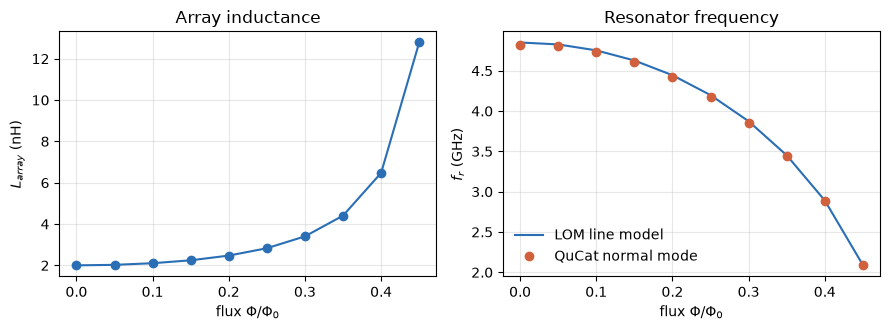

f_r(0) = 4.825 GHz, f_r(0.3 Phi0) = 3.857 GHz (QuCat)
LOM line model: 4.851 / 3.874 GHz


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
ax1.plot(phis, l_arr, "o-", color="#2a6fb5")
ax1.set(xlabel=r"flux $\Phi/\Phi_0$", ylabel=r"$L_{array}$ (nH)", title="Array inductance")
ax2.plot(phis, f_lom, "-", color="#2a6fb5", label="LOM line model")
ax2.plot(phis, f_qucat, "o", color="#d1603d", label="QuCat normal mode")
ax2.set(xlabel=r"flux $\Phi/\Phi_0$", ylabel=r"$f_r$ (GHz)", title="Resonator frequency")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMG / "tunable_fr_flux.png", dpi=110)
plt.show()
i3 = int(np.argmin(abs(phis - 0.3)))
print(f"f_r(0) = {f_qucat[0]:.3f} GHz, f_r(0.3 Phi0) = {f_qucat[i3]:.3f} GHz (QuCat)")
print(f"LOM line model: {f_lom[0]:.3f} / {f_lom[i3]:.3f} GHz")

The frequency falls as |Phi| grows because the SQUIDs' inductance rises as 1/|cos(pi Phi/Phi0)|. These are lumped-model
estimates (component formulas and calibration), not FEM results. Re-solving this chip in FEM needs the simulation PC
and is not part of this notebook.